# Практическая работа №1 «Нечёткие отношения»

**Предметная область:** адаптивный круиз-контроль автомобиля (Adaptive Cruise Control, ACC) - система, которая
поддерживает безопасную дистанцию до впереди идущей машины, автоматически управляя торможением.

## 1. Подключение библиотек

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from IPython.display import display

pd.set_option('display.precision', 2)
pd.set_option('display.width', 200)

plt.rcParams.update({
    'figure.dpi': 110,
    'font.size': 10,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

# Фиксированный порядок цветов: цвет закреплён за номером множества в переменной
COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']

## 2. Предметная область и допущения

Автомобиль с круиз-контролем едет за другой машиной. Если впереди идущая машина медленнее, дистанция сокращается, и
система должна решить, насколько сильно тормозить. Водитель решает эту задачу «нечётко»: «догоняем быстро - до
столкновения остаётся мало времени - нужно тормозить сильно». Именно такие рассуждения формализуются нечёткими
отношениями.

Используются три лингвистические переменные:

| Обозначение | Переменная | Единицы | Универсум | Обоснование диапазона |
|---|---|---|---|---|
| V | скорость сближения с машиной впереди | м/с | 0, 2, …, 20 (11 точек) | 20 м/с ≈ 72 км/ч - разница скоростей при подъезде к стоящей пробке на загородной трассе; отрицательные значения (машина удаляется) торможения не требуют и не рассматриваются |
| T | время до столкновения (Time To Collision, TTC) | с | 0, 1, …, 10 (11 точек) | TTC ≈ 1–1.5 с и меньше - критическая ситуация, 3–4 с - зона предупреждения, более 5–6 с - спокойное движение |
| A | замедление (сила торможения) | м/с² | 0, 1, …, 9 (10 точек) | штатное торможение круиз-контроля ограничено несколькими м/с² из соображений комфорта; 8–9 м/с² - физический предел сцепления шин на сухом асфальте |

Время до столкновения вычисляется как $TTC = D / V$, где $D$ - дистанция до машины впереди. Поэтому правило
«быстрое сближение -> малое TTC» строго верно только при фиксированной дистанции. Допущение работы: рассматривается
типичная для трассы дистанция около 30 м.

Методические указания требуют строить отношения в виде матриц. Матрица существует
только для конечного числа значений, поэтому каждая переменная задаётся на конечном наборе точек, а нечёткое множество -
вектором степеней принадлежности в этих точках. Число точек (10–11) выбрано так, чтобы матрицы оставались читаемыми в
отчёте, а графики - информативными.

## 3. Программная реализация базовых объектов

* функции принадлежности `trapmf` и `trimf`;
* класс `FuzzySet` - нечёткое множество на дискретном универсуме. Помимо вектора степеней принадлежности он хранит
  исходную непрерывную функцию: она нужна, чтобы рисовать форму множества и выполнять сдвиг;
* модификаторы множеств (дополнение, «очень», «более-менее», нормализация, сдвиг);
* класс `LinguisticVariable` - переменная со своим универсумом и набором термов;
* операции над отношениями: построение, свёртка, вывод.

In [2]:
def trapmf(x, a, b, c, d):
    # Трапециевидная функция принадлежности; при a == b (или c == d) соответствующий склон вертикальный
    x = np.asarray(x, dtype=float)
    y = np.zeros_like(x)
    if b > a:
        y = np.where((x > a) & (x < b), (x - a) / (b - a), y)
    y = np.where((x >= b) & (x <= c), 1.0, y)
    if d > c:
        y = np.where((x > c) & (x < d), (d - x) / (d - c), y)
    return y


def trimf(x, a, b, c):
    # Треугольная функция принадлежности - частный случай трапеции с вершиной в точке b
    return trapmf(x, a, b, b, c)


MF_TYPES = {'trap': trapmf, 'tri': trimf}


class FuzzySet:
    # Нечёткое множество на дискретном универсуме

    def __init__(self, name, universe, mu, func=None):
        self.name = name
        self.universe = np.asarray(universe, dtype=float)
        self.mu = np.clip(np.asarray(mu, dtype=float), 0.0, 1.0)
        # func - непрерывная функция принадлежности (для графиков и сдвига); если её нет, используется интерполяция
        self.func = func if func is not None else (lambda x: np.interp(x, self.universe, self.mu))

    @classmethod
    def from_mf(cls, name, universe, kind, params):
        f = MF_TYPES[kind]
        func = lambda x, f=f, p=params: f(x, *p)
        return cls(name, universe, func(universe), func)

    @property
    def height(self):
        # Высота множества - наибольшая степень принадлежности
        return float(self.mu.max())

    # --- модификаторы (изменения множества A -> A') ---
    def complement(self):
        return FuzzySet(f'НЕ {self.name}', self.universe, 1 - self.mu, lambda x: 1 - self.func(x))

    def very(self):
        return FuzzySet(f'очень {self.name}', self.universe, self.mu ** 2, lambda x: self.func(x) ** 2)

    def more_or_less(self):
        return FuzzySet(f'более-менее {self.name}', self.universe, np.sqrt(self.mu), lambda x: np.sqrt(self.func(x)))

    def normalized(self):
        h = self.height if self.height > 0 else 1.0
        return FuzzySet(f'норм. {self.name}', self.universe, self.mu / h, lambda x: np.clip(self.func(x) / h, 0, 1))

    def shifted(self, delta):
        sign = '+' if delta >= 0 else '−'
        return FuzzySet(f'{self.name} {sign}{abs(delta):g}', self.universe,
                        self.func(self.universe - delta), lambda x: self.func(x - delta))

    def __and__(self, other):
        return FuzzySet(f'{self.name} И {other.name}', self.universe, np.minimum(self.mu, other.mu))

    def __or__(self, other):
        return FuzzySet(f'{self.name} ИЛИ {other.name}', self.universe, np.maximum(self.mu, other.mu))

    def __repr__(self):
        return f'FuzzySet({self.name!r}, height={self.height:.2f})'


class LinguisticVariable:
    # Лингвистическая переменная: универсум и набор нечётких множеств (термов)

    def __init__(self, symbol, name, unit, universe):
        self.symbol, self.name, self.unit = symbol, name, unit
        self.universe = np.asarray(universe, dtype=float)
        self.sets = {}

    def add_set(self, term, kind, params):
        self.sets[term] = FuzzySet.from_mf(term, self.universe, kind, params)
        return self.sets[term]

    def __getitem__(self, term):
        return self.sets[term]

    def labels(self):
        return [f'{self.symbol}={v:g}' for v in self.universe]

    def table(self):
        # Таблица степеней принадлежности всех термов во всех точках универсума
        return pd.DataFrame({t: s.mu for t, s in self.sets.items()}, index=self.labels()).T

In [3]:
def relation(A, B):
    # Продукционное отношение A -> B через пересечение, формула (1): R[i, j] = min(muA(x_i), muB(y_j))
    return np.minimum.outer(A.mu, B.mu)


def maxmin(R, S):
    # Свёртка (max-min композиция) отношений, формула (2)
    return np.max(np.minimum(R[:, :, None], S[None, :, :]), axis=1)


def modus_ponens(A_prime, R, Y, name="B'"):
    # B' = A' o R, формула (3)
    mu = np.max(np.minimum(A_prime.mu[:, None], R), axis=0)
    return FuzzySet(name, Y.universe, mu)


def modus_tollens(R, B_prime, X, name="A'"):
    # A' = R o B', формула (4)
    mu = np.max(np.minimum(R, B_prime.mu[None, :]), axis=1)
    return FuzzySet(name, X.universe, mu)


def rel_frame(R, X, Y):
    # Матрица отношения в виде подписанной таблицы: строки - X, столбцы - Y
    return pd.DataFrame(R, index=X.labels(), columns=Y.labels())

In [4]:
def plot_variable(var, ax, extra=()):
    # Функции принадлежности переменной: линия - непрерывная форма, точки - значения на дискретном универсуме
    xs = np.linspace(var.universe.min(), var.universe.max(), 400)
    for i, (term, fs) in enumerate(var.sets.items()):
        ax.plot(xs, fs.func(xs), color=COLORS[i % len(COLORS)], lw=2, label=term)
        ax.plot(var.universe, fs.mu, 'o', color=COLORS[i % len(COLORS)], ms=5)
    for fs, style in extra:
        ax.plot(xs, fs.func(xs), **style)
    ax.set_title(f'{var.symbol} - {var.name}')
    ax.set_xlabel(f'{var.symbol}, {var.unit}')
    ax.set_ylabel('μ')
    ax.set_ylim(-0.05, 1.08)
    ax.set_xticks(var.universe)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=4, fontsize=8, frameon=False)


def plot_relation(R, X, Y, title):
    # Тепловая карта матрицы отношения (с подписанными значениями) и её трёхмерная поверхность
    fig = plt.figure(figsize=(13, 4.8))
    ax1 = fig.add_subplot(1, 2, 1)
    im = ax1.imshow(R, cmap='Blues', vmin=0, vmax=1, origin='lower', aspect='auto')
    ax1.grid(False)
    ax1.set_xticks(range(len(Y.universe)), [f'{v:g}' for v in Y.universe])
    ax1.set_yticks(range(len(X.universe)), [f'{v:g}' for v in X.universe])
    ax1.set_xlabel(f'{Y.symbol} - {Y.name}, {Y.unit}')
    ax1.set_ylabel(f'{X.symbol} - {X.name}, {X.unit}')
    for i in range(R.shape[0]):
        for j in range(R.shape[1]):
            if R[i, j] > 0:
                ax1.text(j, i, f'{R[i, j]:.2f}'.rstrip('0').rstrip('.'), ha='center', va='center', fontsize=7,
                         color='white' if R[i, j] > 0.6 else '#0b0b0b')
    fig.colorbar(im, ax=ax1, label='степень принадлежности')
    ax1.set_title('Матрица отношения (тепловая карта)')

    ax2 = fig.add_subplot(1, 2, 2, projection='3d')
    Yg, Xg = np.meshgrid(Y.universe, X.universe)
    ax2.plot_surface(Yg, Xg, R, cmap='Blues', norm=Normalize(-0.3, 1), edgecolor='#52514e', linewidth=0.3)
    ax2.set_xlabel(f'{Y.symbol}, {Y.unit}')
    ax2.set_ylabel(f'{X.symbol}, {X.unit}')
    ax2.set_zlabel('μ')
    ax2.set_zlim(0, 1)
    ax2.view_init(elev=28, azim=-130)
    ax2.set_title('Поверхность отношения')
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.show()

## 4. Входные данные: N нечётких множеств

Входом приложения является словарь `CONFIG`. Для каждой лингвистической переменной в нём задаются универсум и
произвольное число нечётких множеств (термов) - тип функции принадлежности и её параметры. Чтобы добавить новое
множество, достаточно дописать строку в раздел `sets` нужной переменной; все дальнейшие ячейки работают с любым числом
множеств.

Параметры множеств обоснованы физическим смыслом переменных (раздел 2):
* **V:** «медленное» сближение (до 2 м/с полностью, до 6 м/с частично) - машины едут почти с одинаковой скоростью;
  «быстрое» (от 14 м/с полностью) - подъезд к машине, которая едет более чем на 50 км/ч медленнее;
* **T:** «критическое» TTC (до 1 с полностью, до 2 с частично) - время, за которое водитель едва успевает отреагировать
  (типичное время реакции около 1 с); «малое» - зона предупреждения; «большое» (от 8 с) - опасности нет;
* **A:** «мягкое» торможение (до 1 м/с² полностью) - сброс газа и лёгкое притормаживание; «экстренное» (от 7.5 м/с²) -
  торможение, близкое к пределу сцепления шин.

Соседние множества перекрываются: в точке, где одно множество ослабевает, следующее усиливается. Так переменная
описывается без «дыр», в которых ни один терм не подходит.

In [5]:
CONFIG = {
    'V': {
        'name': 'скорость сближения', 'unit': 'м/с', 'universe': np.arange(0, 21, 2),
        'sets': {
            'медленное': ('trap', (0, 0, 2, 6)),
            'умеренное': ('tri', (4, 8, 12)),
            'быстрое':   ('trap', (10, 14, 20, 20)),
        },
    },
    'T': {
        'name': 'время до столкновения', 'unit': 'с', 'universe': np.arange(0, 11, 1),
        'sets': {
            'критическое': ('trap', (0, 0, 1, 2)),
            'малое':       ('tri', (1, 2.5, 4)),
            'достаточное': ('tri', (3, 5, 7)),
            'большое':     ('trap', (6, 8, 10, 10)),
        },
    },
    'A': {
        'name': 'замедление', 'unit': 'м/с²', 'universe': np.arange(0, 10, 1),
        'sets': {
            'мягкое':     ('trap', (0, 0, 1, 2.5)),
            'умеренное':  ('tri', (1.5, 3, 4.5)),
            'сильное':    ('tri', (4, 5.5, 7)),
            'экстренное': ('trap', (6, 7.5, 9, 9)),
        },
    },
}


def build_variables(config):
    variables = {}
    for symbol, cfg in config.items():
        var = LinguisticVariable(symbol, cfg['name'], cfg['unit'], cfg['universe'])
        for term, (kind, params) in cfg['sets'].items():
            var.add_set(term, kind, params)
        variables[symbol] = var
    return variables


VARS = build_variables(CONFIG)
V, T, A = VARS['V'], VARS['T'], VARS['A']
print(f'Всего нечётких множеств на входе: {sum(len(v.sets) for v in VARS.values())}')
for var in VARS.values():
    print(f'\n{var.symbol} - {var.name}, {var.unit}')
    display(var.table())

Всего нечётких множеств на входе: 11

V - скорость сближения, м/с


,V=0,V=2,V=4,V=6,V=8,V=10,V=12,V=14,V=16,V=18,V=20
медленное,1.0,1.0,0.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
умеренное,0.0,0.0,0.0,0.5,1.0,0.5,0.0,0.0,0.0,0.0,0.0
быстрое,0.0,0.0,0.0,0.0,0.0,0.0,0.5,1.0,1.0,1.0,1.0



T - время до столкновения, с


,T=0,T=1,T=2,T=3,T=4,T=5,T=6,T=7,T=8,T=9,T=10
критическое,1.0,1.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0
малое,0.0,0.0,0.67,0.67,0.0,0.0,0.0,0.0,0.0,0.0,0.0
достаточное,0.0,0.0,0.00,0.00,0.5,1.0,0.5,0.0,0.0,0.0,0.0
большое,0.0,0.0,0.00,0.00,0.0,0.0,0.0,0.5,1.0,1.0,1.0



A - замедление, м/с²


,A=0,A=1,A=2,A=3,A=4,A=5,A=6,A=7,A=8,A=9
мягкое,1.0,1.0,0.33,0.0,0.00,0.00,0.00,0.00,0.0,0.0
умеренное,0.0,0.0,0.33,1.0,0.33,0.00,0.00,0.00,0.0,0.0
сильное,0.0,0.0,0.00,0.0,0.00,0.67,0.67,0.00,0.0,0.0
экстренное,0.0,0.0,0.00,0.0,0.00,0.00,0.00,0.67,1.0,1.0


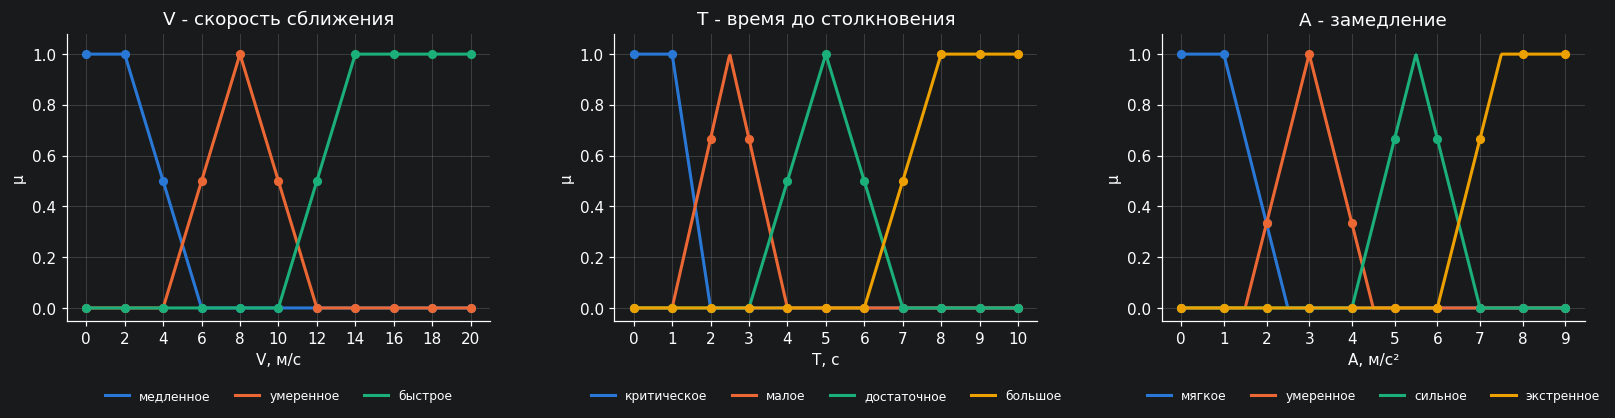

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, var in zip(axes, VARS.values()):
    plot_variable(var, ax)
plt.tight_layout()
plt.show()

На графиках линией показана непрерывная форма функции принадлежности, а точками - её значения на дискретном
универсуме, с которыми работают матрицы. Видно главное следствие дискретизации: узкие множества представлены всего
несколькими точками. Например, «критическое» TTC имеет ненулевую принадлежность только в точках 0 и 1 с. Это
сознательный компромисс между точностью описания и размером матриц; к его последствиям мы вернёмся при анализе правил
вывода (раздел 9).

## 5. Продукционные отношения

Используются два правила, образующие цепочку:

* **R1:** если сближение *быстрое*, то время до столкновения *критическое* - правило отражает физическую связь
  $TTC = D/V$ при фиксированной дистанции;
* **R2:** если время до столкновения *критическое*, то торможение *экстренное* - правило отражает логику систем
  экстренного торможения: при TTC около секунды других способов избежать столкновения уже нет.

Правила выбраны так, чтобы следствие первого совпадало с условием второго. Это позволяет в разделе 7 вывести из них
новое правило свёрткой. Отношения строятся по формуле (1).

R1: быстрое сближение -> критическое TTC, размер (11, 11)


,T=0,T=1,T=2,T=3,T=4,T=5,T=6,T=7,T=8,T=9,T=10
V=0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
V=2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
V=4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
V=6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
V=8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
V=10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
V=12,0.5,0.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
V=14,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
V=16,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
V=18,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


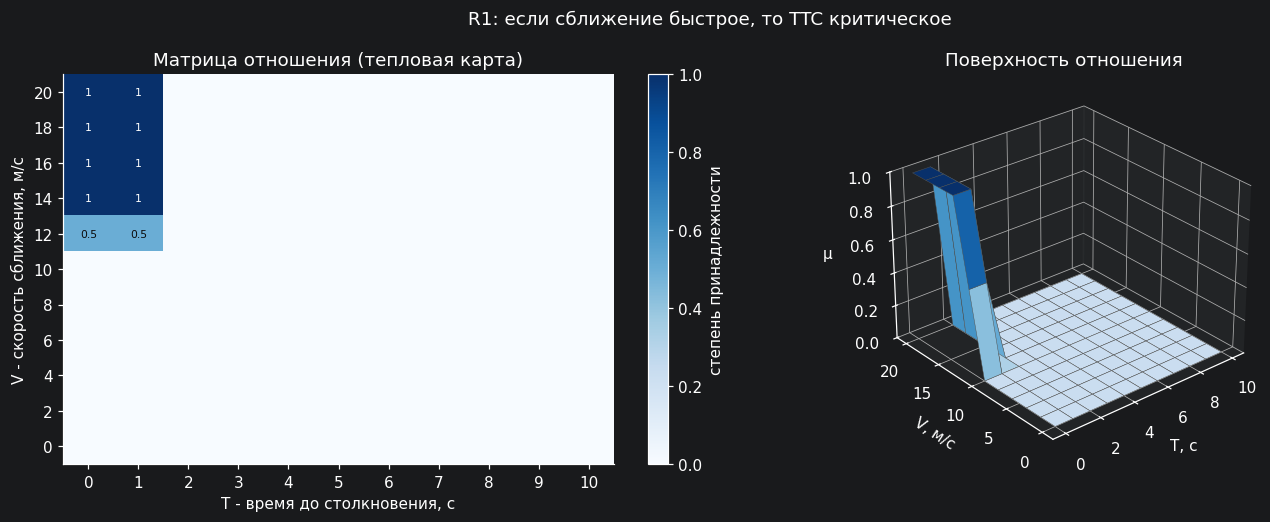

In [6]:
R1 = relation(V['быстрое'], T['критическое'])
print('R1: быстрое сближение -> критическое TTC, размер', R1.shape)
display(rel_frame(R1, V, T))
plot_relation(R1, V, T, 'R1: если сближение быстрое, то TTC критическое')

Матрица R1 ненулевая только в прямоугольнике, где одновременно ненулевые $\mu_{быстрое}(V)$ (V ≥ 12 м/с) и
$\mu_{критическое}(T)$ (T ≤ 1 с). Каждая клетка равна меньшей из двух степеней принадлежности. Поэтому строка V = 12 м/с
целиком «срезана» на уровне 0.5: при таком сближении скорость лишь наполовину «быстрая», и правило действует только в
этой степени. На поверхности это видно как плато высотой 1 в углу «большая скорость сближения - малое TTC» и
ступенька высотой 0.5 на его краю.

R2: критическое TTC -> экстренное торможение, размер (11, 10)


,A=0,A=1,A=2,A=3,A=4,A=5,A=6,A=7,A=8,A=9
T=0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.67,1.0,1.0
T=1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.67,1.0,1.0
T=2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0
T=3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0
T=4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0
T=5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0
T=6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0
T=7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0
T=8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0
T=9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0


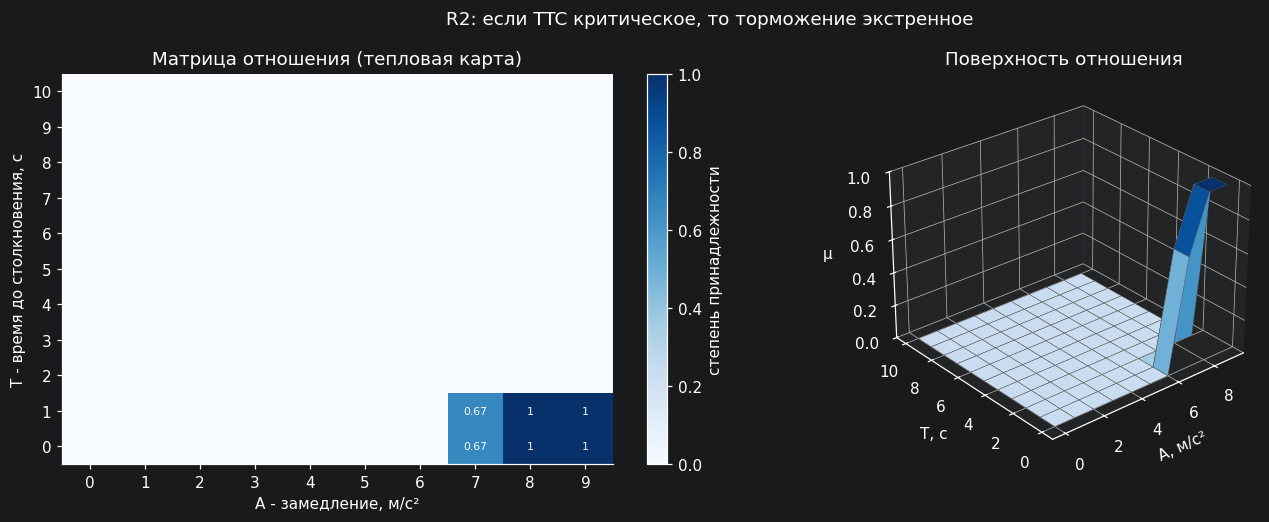

In [7]:
R2 = relation(T['критическое'], A['экстренное'])
print('R2: критическое TTC -> экстренное торможение, размер', R2.shape)
display(rel_frame(R2, T, A))
plot_relation(R2, T, A, 'R2: если TTC критическое, то торможение экстренное')

Отношение R2 устроено так же: оно сосредоточено в углу «TTC ≤ 1 с - замедление ≥ 7 м/с²». Строка A = 7 м/с²
ограничена значением 0.67, так как замедление 7 м/с² лишь частично относится к «экстренному» торможению (оно начинается с
6 м/с², а полностью выполняется с 7.5 м/с²).

## 6. Свёртка отношений: вывод нового правила

Свёртка $R3 = R1 \circ R2$ по формуле (2) «проходит» по промежуточной переменной T: для каждой пары
(скорость сближения, замедление) ищется такое время до столкновения, через которое связь между ними наиболее сильна.
Результат - новое правило, которого не было в исходной базе:

**R3:** если сближение *быстрое*, то торможение *экстренное*.

Размер матрицы: (11 × 11) * (11 × 10) -> 11 × 10.

R3 = R1 o R2: быстрое сближение -> экстренное торможение, размер (11, 10)


,A=0,A=1,A=2,A=3,A=4,A=5,A=6,A=7,A=8,A=9
V=0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0
V=2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0
V=4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0
V=6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0
V=8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0
V=10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0
V=12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.50,0.5,0.5
V=14,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.67,1.0,1.0
V=16,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.67,1.0,1.0
V=18,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.67,1.0,1.0


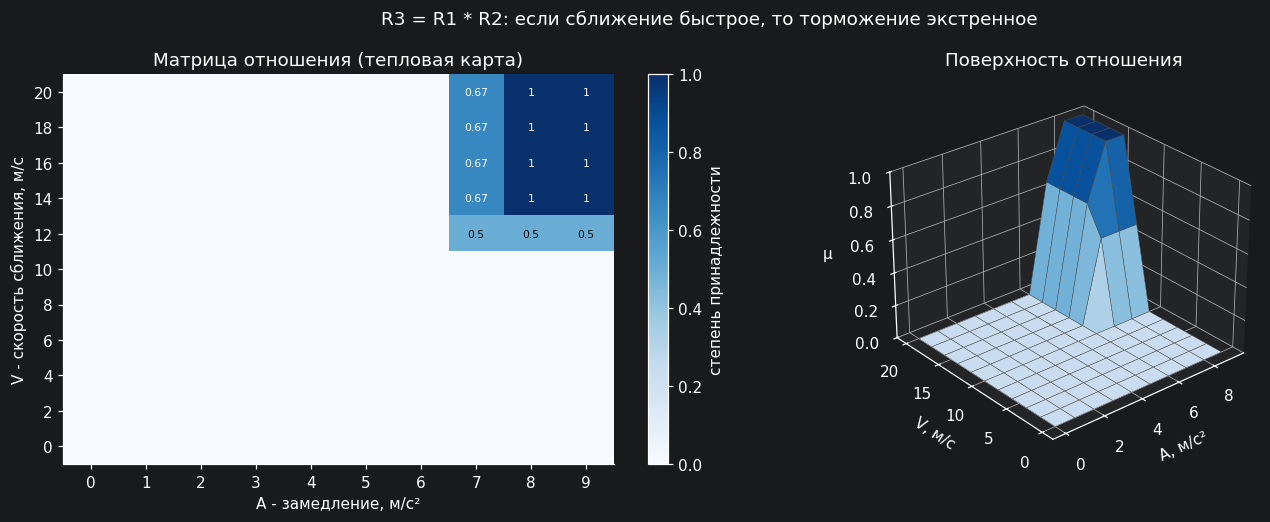

In [9]:
R3 = maxmin(R1, R2)
print('R3 = R1 o R2: быстрое сближение -> экстренное торможение, размер', R3.shape)
display(rel_frame(R3, V, A))
plot_relation(R3, V, A, 'R3 = R1 * R2: если сближение быстрое, то торможение экстренное')

**Проверка результата.** Сравним свёртку с отношением, построенным напрямую по формуле из множеств «быстрое
сближение» и «экстренное торможение». Для правил, построенных через пересечение, справедливо:

$$
(R_{A\to B} \circ R_{B\to C})(x, z) = \max_y \min\left(\mu_A(x), \mu_B(y), \mu_C(z)\right)
= \min\left(\mu_A(x), \mu_C(z), \operatorname{hgt}(B)\right),
$$

где $\operatorname{hgt}(B) = \max_y \mu_B(y)$ - высота промежуточного множества. Если промежуточное множество
нормальное (его высота равна 1), свёртка в точности совпадает с прямым правилом $A \to C$. Если же промежуточное
множество субнормальное, выведенное правило «срезается» на уровне его высоты: логическая цепочка не может быть
увереннее, чем её самое слабое звено.

In [10]:
R3_direct = relation(V['быстрое'], A['экстренное'])
print(f'Высота промежуточного множества «критическое»: {T["критическое"].height:.2f}')
print(f'Максимальное расхождение свёртки и прямого правила: {np.abs(R3 - R3_direct).max():.2e}')

# Демонстрация субнормального промежуточного множества: уверенность в том, что TTC критическое, не выше 0.6
T_crit_weak = FuzzySet('критическое (высота 0.6)', T.universe, np.minimum(T['критическое'].mu, 0.6))
R3_weak = maxmin(relation(V['быстрое'], T_crit_weak), relation(T_crit_weak, A['экстренное']))
print(f'Максимум свёртки при высоте промежуточного множества 0.6: {R3_weak.max():.2f}')

Высота промежуточного множества «критическое»: 1.00
Максимальное расхождение свёртки и прямого правила: 0.00e+00
Максимум свёртки при высоте промежуточного множества 0.6: 0.60


Расхождение равно нулю: множество «критическое» нормальное, поэтому выведенное свёрткой правило совпадает с правилом,
которое эксперт мог бы сформулировать напрямую. Это подтверждает корректность реализации и показывает практический
смысл свёртки: она позволяет **получать новые правила, не формулируя их вручную**, и гарантирует их согласованность с
исходной базой. Пример с субнормальным промежуточным множеством показывает обратную сторону: если звено цепочки
выполняется лишь частично (высота 0.6), выведенное правило ослабевает до того же уровня.

## 7. Изменение направления правил: транспонирование

Транспонирование меняет местами условие и следствие: $R \to K$ превращается в $K \to R$. Получаем обратные правила:
* **R1ᵀ:** если TTC *критическое*, то сближение *быстрое*;
* **R3ᵀ:** если торможение *экстренное*, то сближение *быстрое*.

Такие правила имеют диагностический смысл: по наблюдаемому следствию они указывают на вероятную причину. Например,
система анализа поездок, увидев экстренное торможение, может заключить, что водитель слишком быстро догонял машину
впереди.

R1^T: критическое TTC -> быстрое сближение, размер (11, 11)


,V=0,V=2,V=4,V=6,V=8,V=10,V=12,V=14,V=16,V=18,V=20
T=0,0.0,0.0,0.0,0.0,0.0,0.0,0.5,1.0,1.0,1.0,1.0
T=1,0.0,0.0,0.0,0.0,0.0,0.0,0.5,1.0,1.0,1.0,1.0
T=2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
T=3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
T=4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
T=5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
T=6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
T=7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
T=8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
T=9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


R3^T: экстренное торможение -> быстрое сближение, размер (10, 11)


,V=0,V=2,V=4,V=6,V=8,V=10,V=12,V=14,V=16,V=18,V=20
A=0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00
A=1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00
A=2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00
A=3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00
A=4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00
A=5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00
A=6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00
A=7,0.0,0.0,0.0,0.0,0.0,0.0,0.5,0.67,0.67,0.67,0.67
A=8,0.0,0.0,0.0,0.0,0.0,0.0,0.5,1.00,1.00,1.00,1.00
A=9,0.0,0.0,0.0,0.0,0.0,0.0,0.5,1.00,1.00,1.00,1.00


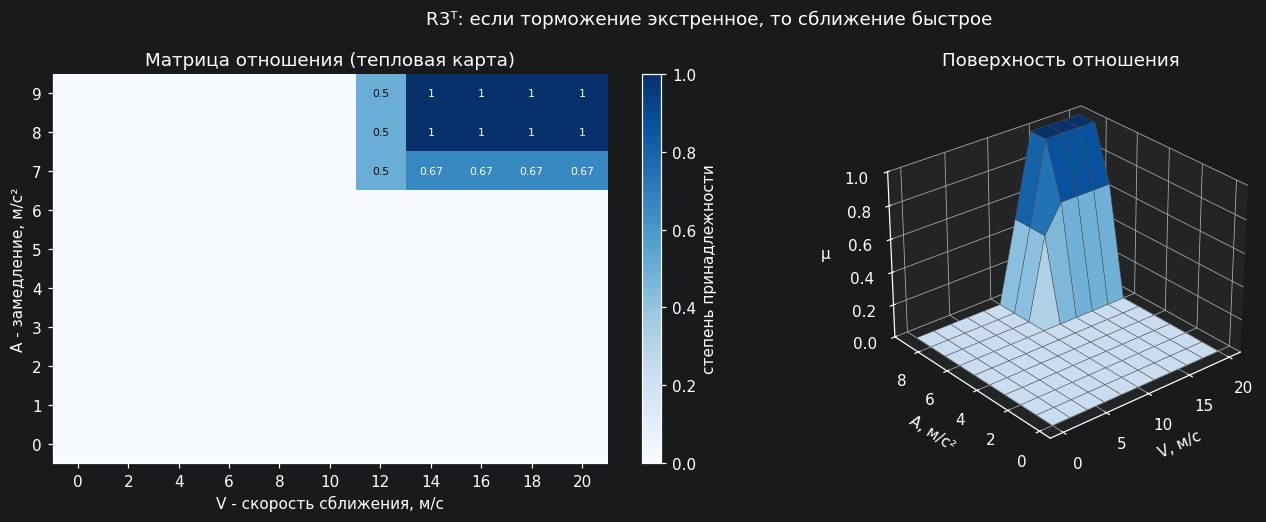

R1^T совпадает с отношением, построенным напрямую по правилу «критическое -> быстрое»: True


In [11]:
R1T = R1.T
R3T = R3.T
print('R1^T: критическое TTC -> быстрое сближение, размер', R1T.shape)
display(rel_frame(R1T, T, V))
print('R3^T: экстренное торможение -> быстрое сближение, размер', R3T.shape)
display(rel_frame(R3T, A, V))
plot_relation(R3T, A, V, 'R3ᵀ: если торможение экстренное, то сближение быстрое')

print('R1^T совпадает с отношением, построенным напрямую по правилу «критическое -> быстрое»:',
      np.array_equal(R1T, relation(T['критическое'], V['быстрое'])))

Транспонированная матрица совпадает с матрицей, построенной напрямую из правила «критическое -> быстрое». Причина в том,
что отношение (1) построено через пересечение, а операция min симметрична: $\min(a, b) = \min(b, a)$. Поэтому такое
отношение описывает скорее **связь** «быстрое сближение и критическое TTC встречаются вместе», чем направленную
импликацию. Это важное ограничение подхода Мамдани: прямое и обратное правила для него неразличимы, хотя в логике
«если A, то B» и «если B, то A» - разные утверждения. На практике это допустимо, если обратное правило физически
осмысленно, как в нашем случае.

## 8. Дополнение нечётких множеств

Дополнение $\neg A$ с функцией принадлежности $1 - \mu_A$ соответствует отрицанию: «НЕ быстрое сближение»,
«НЕ критическое TTC», «НЕ экстренное торможение».

В нечёткой логике, в отличие от классической, не выполняются законы исключённого третьего ($A \cup \neg A = X$) и
противоречия ($A \cap \neg A = \varnothing$). Проверим это на наших множествах.

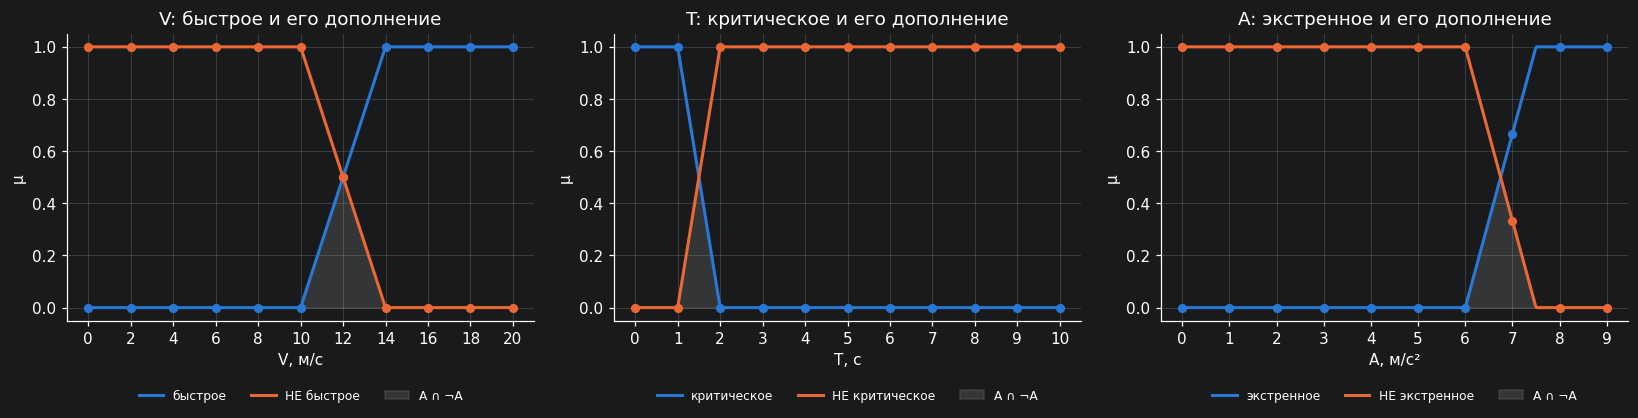

,max(A ∩ ¬A) (в классике 0),min(A ∪ ¬A) (в классике 1)
множество,,
V: быстрое,0.50,0.50
T: критическое,0.00,1.00
A: экстренное,0.33,0.67


In [12]:
pairs = [(V, 'быстрое'), (T, 'критическое'), (A, 'экстренное')]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
rows = []
for ax, (var, term) in zip(axes, pairs):
    s, ns = var[term], var[term].complement()
    xs = np.linspace(var.universe.min(), var.universe.max(), 400)
    ax.plot(xs, s.func(xs), color=COLORS[0], lw=2, label=s.name)
    ax.plot(xs, ns.func(xs), color=COLORS[1], lw=2, label=ns.name)
    ax.plot(var.universe, s.mu, 'o', color=COLORS[0], ms=5)
    ax.plot(var.universe, ns.mu, 'o', color=COLORS[1], ms=5)
    ax.fill_between(xs, np.minimum(s.func(xs), ns.func(xs)), color='#888888', alpha=0.25, label='A ∩ ¬A')
    ax.set_title(f'{var.symbol}: {term} и его дополнение')
    ax.set_xlabel(f'{var.symbol}, {var.unit}')
    ax.set_ylabel('μ')
    ax.set_xticks(var.universe)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=4, fontsize=8, frameon=False)
    rows.append({'множество': f'{var.symbol}: {term}',
                 'max(A ∩ ¬A) (в классике 0)': (s & ns).height,
                 'min(A ∪ ¬A) (в классике 1)': (s | ns).mu.min()})
plt.tight_layout()
plt.show()
display(pd.DataFrame(rows).set_index('множество'))

В точках, где множество выполняется частично, элемент одновременно в какой-то степени принадлежит и множеству, и его
дополнению. Например, сближение 12 м/с - «быстрое» и «не быстрое» в степени 0.5. Это не ошибка, а суть нечёткой логики:
граница между «быстро» и «не быстро» размыта. В нашей дискретизации пересечение $A \cap \neg A$ достигает 0.5 для V и
0.33 для A, а для TTC равно нулю: у множества «критическое» в точках универсума нет промежуточных значений (только 1 и 0).
Серая область на графиках показывает пересечение непрерывных функций, а таблица - значения в точках универсума,
с которыми работают матрицы.

**Дополнение и отношения.** Построим правило на дополнениях «НЕ быстрое сближение -> НЕ экстренное торможение» и сравним
его с дополнением матрицы R3. Это разные объекты: по закону де Моргана
$1 - \min(\mu_A, \mu_C) = \max(1 - \mu_A, 1 - \mu_C)$, то есть дополнение матрицы - это «НЕ быстрое **ИЛИ** НЕ
экстренное», а не правило на дополнениях.

Правило «НЕ быстрое -> НЕ экстренное»:


,A=0,A=1,A=2,A=3,A=4,A=5,A=6,A=7,A=8,A=9
V=0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.33,0.0,0.0
V=2,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.33,0.0,0.0
V=4,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.33,0.0,0.0
V=6,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.33,0.0,0.0
V=8,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.33,0.0,0.0
V=10,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.33,0.0,0.0
V=12,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.33,0.0,0.0
V=14,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0
V=16,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0
V=18,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0


Совпадает с max(1-μ_быстрое, 1-μ_экстренное): True
Отличие правила на дополнениях от дополнения матрицы R3: 1.00


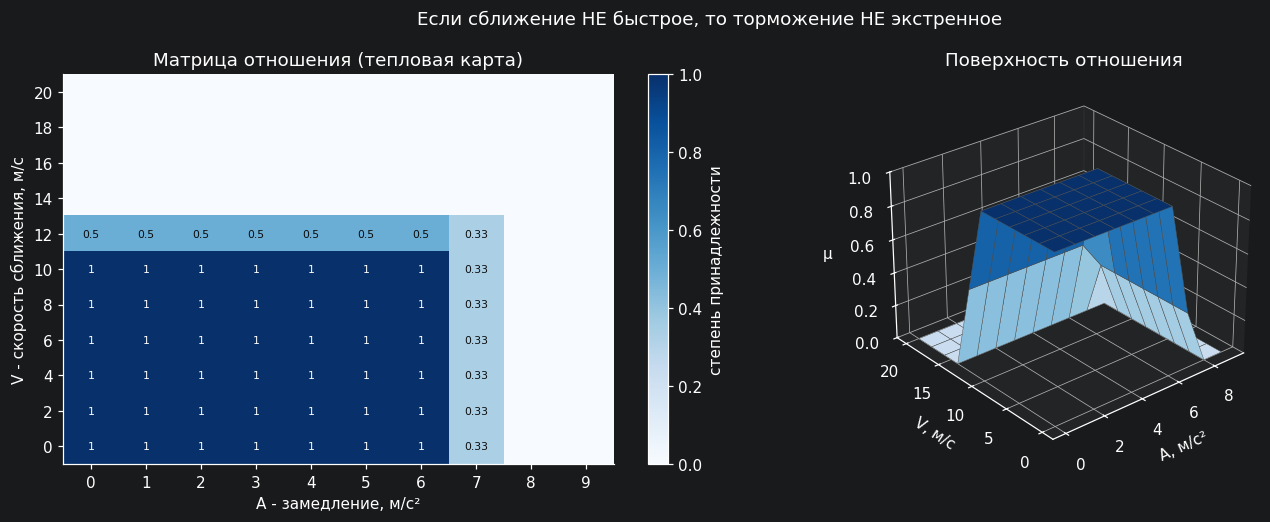

In [13]:
R_not = relation(V['быстрое'].complement(), A['экстренное'].complement())
R3_compl = 1 - R3
print('Правило «НЕ быстрое -> НЕ экстренное»:')
display(rel_frame(R_not, V, A))
print('Совпадает с max(1-μ_быстрое, 1-μ_экстренное):',
      np.allclose(R3_compl, np.maximum.outer(1 - V['быстрое'].mu, 1 - A['экстренное'].mu)))
print(f'Отличие правила на дополнениях от дополнения матрицы R3: {np.abs(R_not - R3_compl).max():.2f}')
plot_relation(R_not, V, A, 'Если сближение НЕ быстрое, то торможение НЕ экстренное')

Правило на дополнениях покрывает «спокойную» область: при медленном сближении экстренное торможение не нужно. Его
матрица заметно отличается от $1 - R3$ (до 1.0 в отдельных клетках), что подтверждает закон де Моргана: отрицание правила
и правило на отрицаниях - не одно и то же.

## 9. Правила вывода

### 9.1. Modus ponens: каким будет торможение?

По формуле (3) для выведенного правила R3 «быстрое сближение -> экстренное торможение» найдём, каким должно быть
торможение $B'$ при изменённой скорости сближения $A'$. Подставив (1) в (3), получим:

$$
\mu_{B'}(y) = \max_x \min\left(\mu_{A'}(x), \mu_A(x), \mu_B(y)\right) = \min\left(\operatorname{hgt}(A' \cap A),\ \mu_B(y)\right),
$$

то есть вывод - это исходное следствие $B$, «срезанное» на уровне **степени совпадения** $\operatorname{hgt}(A' \cap A)$
наблюдаемой ситуации с условием правила.

Рассмотрим несколько вариантов $A'$:
* «быстрое» - сама посылка правила (контрольный случай);
* «очень быстрое» ($\mu^2$) и «более-менее быстрое» ($\sqrt{\mu}$) - модификаторы Заде;
* «умеренное +4» - множество «умеренное», сдвинутое на 4 м/с вправо: сближение заметно быстрее умеренного, но ещё не
  вполне быстрое;
* «умеренное» - соседний терм переменной.

,совпадение hgt(A' ∩ A),высота B',B' = B,"вывод через цепочку R1, R2 совпадает"
A',,,,
быстрое,1.0,1.0,True,True
очень быстрое,1.0,1.0,True,True
более-менее быстрое,1.0,1.0,True,True
умеренное +4,0.5,0.5,False,True
умеренное,0.0,0.0,False,True


,A=0,A=1,A=2,A=3,A=4,A=5,A=6,A=7,A=8,A=9
B' при A' = быстрое,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.67,1.0,1.0
B' при A' = очень быстрое,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.67,1.0,1.0
B' при A' = более-менее быстрое,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.67,1.0,1.0
B' при A' = умеренное +4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.50,0.5,0.5
B' при A' = умеренное,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0


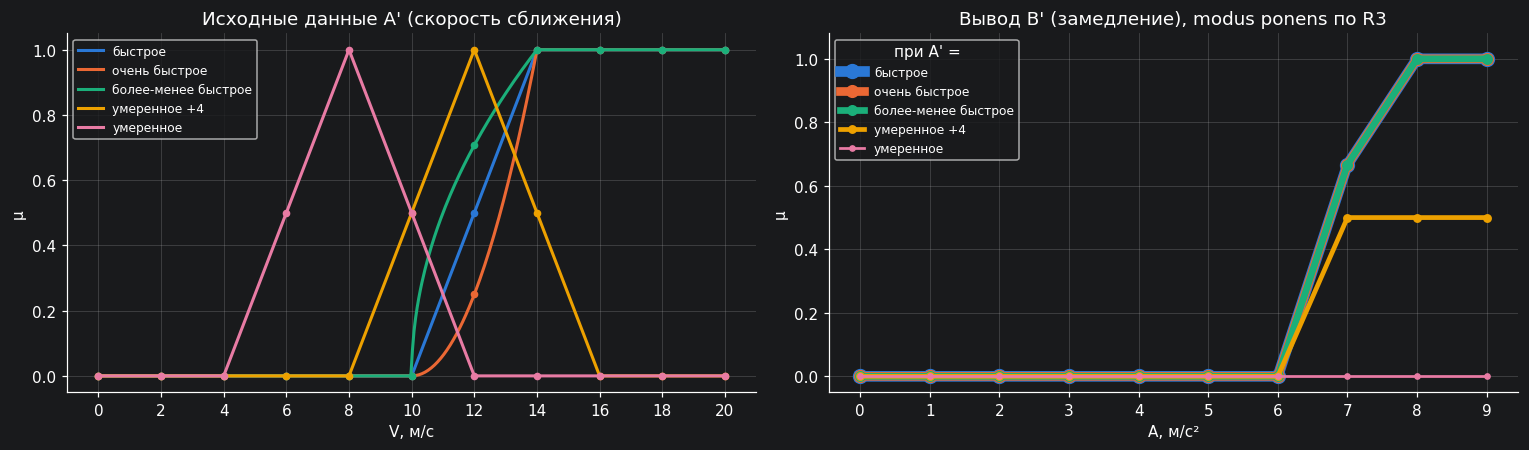

In [14]:
fast = V['быстрое']
A_primes = [fast, fast.very(), fast.more_or_less(), V['умеренное'].shifted(4), V['умеренное']]

rows, B_primes = [], []
for Ap in A_primes:
    Bp = modus_ponens(Ap, R3, A, name=f"B' при A' = {Ap.name}")
    # Проверка ассоциативности: вывод по цепочке (A' o R1) o R2 должен совпадать с A' o (R1 o R2)
    T_prime = modus_ponens(Ap, R1, T)
    Bp_chain = modus_ponens(T_prime, R2, A)
    B_primes.append(Bp)
    rows.append({"A'": Ap.name,
                 "совпадение hgt(A' ∩ A)": (Ap & fast).height,
                 "высота B'": Bp.height,
                 "B' = B": np.allclose(Bp.mu, A['экстренное'].mu),
                 "вывод через цепочку R1, R2 совпадает": np.allclose(Bp.mu, Bp_chain.mu)})
display(pd.DataFrame(rows).set_index("A'"))
display(pd.DataFrame({b.name: b.mu for b in B_primes}, index=A.labels()).T)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))
xs = np.linspace(0, 20, 400)
for i, Ap in enumerate(A_primes):
    ax1.plot(xs, Ap.func(xs), color=COLORS[i], lw=2, label=Ap.name)
    ax1.plot(V.universe, Ap.mu, 'o', color=COLORS[i], ms=4)
ax1.set_title("Исходные данные A' (скорость сближения)")
ax1.set_xlabel('V, м/с'); ax1.set_ylabel('μ'); ax1.set_xticks(V.universe); ax1.legend(fontsize=8)
for i, Bp in enumerate(B_primes):
    # линии рисуются без сдвига; совпадающие выводы видны как наложение линий разной толщины
    ax2.plot(A.universe, Bp.mu, 'o-', color=COLORS[i], lw=7 - 1.3 * i, ms=9 - 1.4 * i, label=A_primes[i].name)
ax2.set_title("Вывод B' (замедление), modus ponens по R3")
ax2.set_xlabel('A, м/с²'); ax2.set_ylabel('μ'); ax2.set_xticks(A.universe); ax2.set_ylim(-0.05, 1.08)
ax2.legend(title="при A' =", fontsize=8)
plt.tight_layout()
plt.show()

Результаты modus ponens хорошо интерпретируются:

* при «быстром», «очень быстром» и «более-менее быстром» сближении вывод совпадает с исходным следствием: нужно
  экстренное торможение. Все три множества полностью (со степенью 1) совпадают с посылкой хотя бы в одной точке
  (V ≥ 14 м/с). Модификаторы меняют форму множества на склонах, но не его ядро, поэтому вывод по правилу Мамдани не
  меняется;
* при сближении «умеренное +4» совпадение с посылкой частичное (0.5), и вывод «экстренное торможение» получен лишь со
  степенью 0.5. Ситуация похожа на описанную правилом, но не полностью, и система уверена в выводе только наполовину;
* при «умеренном» сближении вывод пуст. В непрерывном виде множества «умеренное» и «быстрое» пересекаются (около
  11 м/с со степенью 0.25), но в точках универсума с шагом 2 м/с их ненулевые значения не совпадают ни разу. Это прямое
  следствие дискретизации, о котором говорилось в разделе 5: слишком крупный шаг универсума может «потерять»
  перекрытие соседних термов.

Вывод через цепочку исходных правил ($(A' \circ R1) \circ R2$) во всех случаях совпал с выводом по свёрнутому правилу
R3 ($A' \circ (R1 \circ R2)$). Это подтверждает ассоциативность max-min композиции: свёрнутое правило полностью заменяет
цепочку.

**Почему $B'$, как правило, не совпадает с $B$.** Вывод по правилу Мамдани не «пересчитывает» форму следствия, а
только понижает её до степени совпадения. Поэтому $B' = B$ лишь тогда, когда наблюдаемая ситуация полностью
соответствует посылке хотя бы в одной точке, а в остальных случаях $B'$ - срезанная копия $B$.

### 9.2. Modus tollens: каким было сближение?

По формуле (4) решаем обратную задачу: известно, каким оказалось торможение $B'$, требуется оценить скорость сближения
$A'$. Аналогично:

$$
\mu_{A'}(x) = \min\left(\mu_A(x),\ \operatorname{hgt}(B \cap B')\right).
$$

Варианты $B'$:
* «экстренное» - само следствие правила (контрольный случай);
* «более-менее экстренное» ($\sqrt{\mu}$) - вариант, согласованный ранее;
* «сильное +1» - множество «сильное», сдвинутое на 1 м/с² вправо: торможение на границе сильного и экстренного;
* «сильное» - соседний терм.

Дополнительно проверим связь с транспонированием: вывод по формуле (4) должен совпадать с modus ponens по
транспонированному правилу, $R \circ B' = B' \circ R^T$.

,совпадение hgt(B ∩ B'),высота A',A' = A,совпадает с B' o R3^T
B',,,,
экстренное,1.00,1.00,True,True
более-менее экстренное,1.00,1.00,True,True
сильное +1,0.67,0.67,False,True
сильное,0.00,0.00,False,True


,V=0,V=2,V=4,V=6,V=8,V=10,V=12,V=14,V=16,V=18,V=20
A' при B' = экстренное,0.0,0.0,0.0,0.0,0.0,0.0,0.5,1.00,1.00,1.00,1.00
A' при B' = более-менее экстренное,0.0,0.0,0.0,0.0,0.0,0.0,0.5,1.00,1.00,1.00,1.00
A' при B' = сильное +1,0.0,0.0,0.0,0.0,0.0,0.0,0.5,0.67,0.67,0.67,0.67
A' при B' = сильное,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00


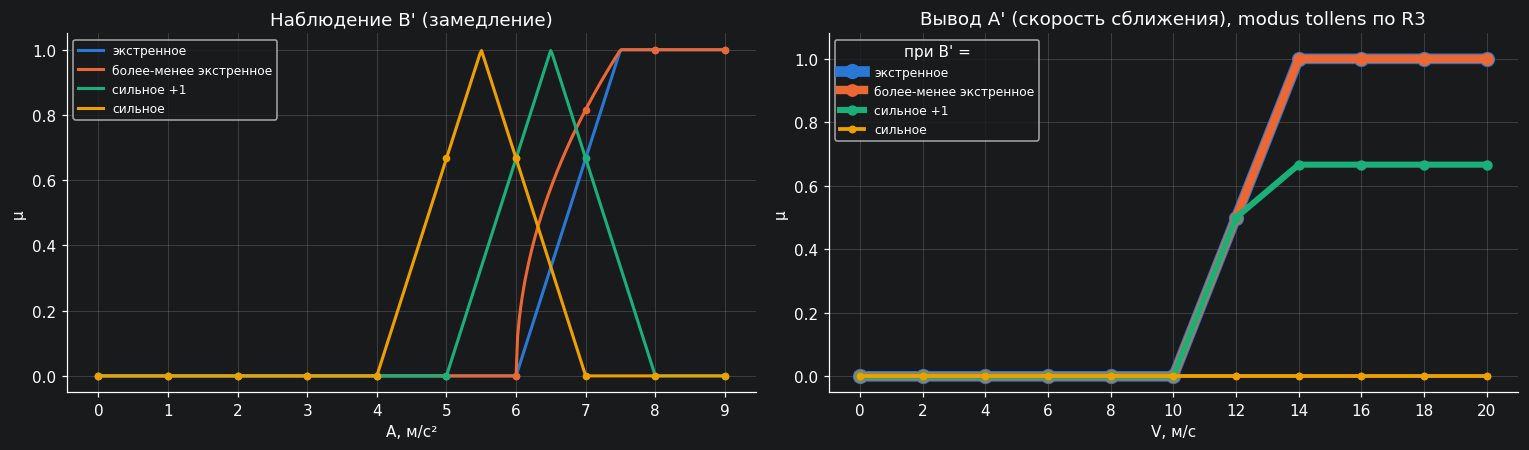

In [15]:
emerg = A['экстренное']
B_primes_mt = [emerg, emerg.more_or_less(), A['сильное'].shifted(1), A['сильное']]

rows, A_inferred = [], []
for Bp in B_primes_mt:
    Ap = modus_tollens(R3, Bp, V, name=f"A' при B' = {Bp.name}")
    Ap_T = modus_ponens(Bp, R3T, V)
    A_inferred.append(Ap)
    rows.append({"B'": Bp.name,
                 "совпадение hgt(B ∩ B')": (Bp & emerg).height,
                 "высота A'": Ap.height,
                 "A' = A": np.allclose(Ap.mu, fast.mu),
                 "совпадает с B' o R3^T": np.allclose(Ap.mu, Ap_T.mu)})
display(pd.DataFrame(rows).set_index("B'"))
display(pd.DataFrame({a.name: a.mu for a in A_inferred}, index=V.labels()).T)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))
xs = np.linspace(0, 9, 400)
for i, Bp in enumerate(B_primes_mt):
    ax1.plot(xs, Bp.func(xs), color=COLORS[i], lw=2, label=Bp.name)
    ax1.plot(A.universe, Bp.mu, 'o', color=COLORS[i], ms=4)
ax1.set_title("Наблюдение B' (замедление)")
ax1.set_xlabel('A, м/с²'); ax1.set_ylabel('μ'); ax1.set_xticks(A.universe); ax1.legend(fontsize=8)
for i, Ap in enumerate(A_inferred):
    ax2.plot(V.universe, Ap.mu, 'o-', color=COLORS[i], lw=7 - 1.5 * i, ms=9 - 1.6 * i, label=B_primes_mt[i].name)
ax2.set_title("Вывод A' (скорость сближения), modus tollens по R3")
ax2.set_xlabel('V, м/с'); ax2.set_ylabel('μ'); ax2.set_xticks(V.universe); ax2.set_ylim(-0.05, 1.08)
ax2.legend(title="при B' =", fontsize=8)
plt.tight_layout()
plt.show()

Обратный вывод ведёт себя симметрично прямому:
* «экстренное» и «более-менее экстренное» торможение полностью согласуются со следствием правила, и система заключает,
  что сближение было быстрым со степенью 1;
* торможение «сильное +1» совпадает со следствием частично (0.67), поэтому вывод о быстром сближении получен со
  степенью 0.67;
* «сильное» торможение в точках универсума не пересекается с «экстренным», поэтому правило R3 ничего не говорит о
  причине такого торможения. Для объяснения нужно другое правило (например, «умеренное сближение -> сильное
  торможение»).

Вывод по формуле (4) во всех случаях совпал с modus ponens по транспонированному правилу $R3^T$. Это связывает
дополнительные задания между собой: **транспонирование превращает обратный вывод в прямой**.

**Замечание о классическом modus tollens.** В классической логике modus tollens выглядит иначе: из «если A, то B» и
«НЕ B» следует «НЕ A». Формула методических указаний (4) реализует обратный вывод по нечёткому отношению. Если подставить
в неё дополнение $B' = \neg B$, отношение Мамдани (1) даст не $\neg A$, а $A$, срезанное на уровне
$\operatorname{hgt}(B \cap \neg B)$, то есть «быстрое сближение» с небольшой степенью. Причина та же, что в разделе 8:
операция min описывает связь, а не импликацию. Для классического поведения нужны настоящие нечёткие импликации
(Заде, Лукасевича и др.). Это возможное направление творческой части работы.

## 10. Творческая часть: нечёткие импликации вместо отношения Мамдани

### 10.1. Постановка

В разделах 8–10 обнаружились три особенности отношения (1), построенного через пересечение:
1. транспонированное правило совпадает с прямым - направление «если - то» теряется;
2. вход «НЕ быстрое сближение» приводит к выводу «экстренное торможение» со степенью 0.5;
3. modus tollens по формуле (4) не реализует классическую схему «из A -> B и НЕ B следует НЕ A».

Общая причина: операция min - это **конъюнкция** (t-норма), а не импликация. Отношение Мамдани говорит «быстрое
сближение и экстренное торможение *встречаются вместе*», но не «быстрое сближение *требует* экстренного торможения».
Проверим гипотезу: если заменить min на настоящие нечёткие импликации, все три особенности должны исчезнуть.

Рассматриваются четыре классические импликации [Заде; Клини–Дайнс; Лукасевич; Гёдель], где $a = \mu_A(x)$,
$b = \mu_B(y)$:

| Импликация | Формула $I(a, b)$ | Идея |
|---|---|---|
| Мамдани (для сравнения) | $\min(a, b)$ | конъюнкция «A и B» |
| Заде | $\max(1 - a, \min(a, b))$ | «не A, или A и B» |
| Клини–Дайнс | $\max(1 - a, b)$ | «не A, или B» - прямой перенос классической формулы $\neg A \lor B$ |
| Лукасевич | $\min(1, 1 - a + b)$ | истинность падает пропорционально тому, насколько $b$ меньше $a$ |
| Гёдель | $1$, если $a \le b$; иначе $b$ | правило выполнено полностью, если следствие не слабее посылки |

Правило строится так же, как в (1), но через импликацию:

$$
R_{A \to B}(x, y) = I\left(\mu_A(x), \mu_B(y)\right), \tag{5}
$$

а свёртка, транспонирование и правила вывода (2)–(4) остаются без изменений. Так сравнение получается честным:
меняется только способ построения матрицы отношения.

In [16]:
IMPLICATIONS = {
    'Мамдани':     lambda a, b: np.minimum(a, b),
    'Заде':        lambda a, b: np.maximum(1 - a, np.minimum(a, b)),
    'Клини–Дайнс': lambda a, b: np.maximum(1 - a, b),
    'Лукасевич':   lambda a, b: np.minimum(1.0, 1 - a + b),
    'Гёдель':      lambda a, b: np.where(a <= b, 1.0, b),
}


def relation_impl(A, B, impl):
    # Отношение A -> B через нечёткую импликацию, формула (5)
    f = IMPLICATIONS[impl]
    return f(A.mu[:, None], B.mu[None, :])


# Проверка: на чётких значениях {0, 1} импликация должна совпадать с классической таблицей истинности A -> B
truth = pd.DataFrame(
    {impl: [float(f(np.array(a), np.array(b))) for a, b in [(0, 0), (0, 1), (1, 0), (1, 1)]]
     for impl, f in IMPLICATIONS.items()},
    index=['A=0, B=0', 'A=0, B=1', 'A=1, B=0', 'A=1, B=1'])
truth['классическая A->B'] = [1.0, 1.0, 0.0, 1.0]
display(truth)

,Мамдани,Заде,Клини–Дайнс,Лукасевич,Гёдель,классическая A->B
"A=0, B=0",0.0,1.0,1.0,1.0,1.0,1.0
"A=0, B=1",0.0,1.0,1.0,1.0,1.0,1.0
"A=1, B=0",0.0,0.0,0.0,0.0,0.0,0.0
"A=1, B=1",1.0,1.0,1.0,1.0,1.0,1.0


На чётких значениях все четыре импликации совпадают с классической таблицей истинности. Отношение Мамдани - нет:
для ложной посылки (A = 0) оно даёт 0, тогда как в логике «из ложной посылки следует что угодно» и импликация истинна.
Это и есть формальное отличие конъюнкции от импликации.

### 10.2. Матрицы правила «быстрое сближение -> экстренное торможение»

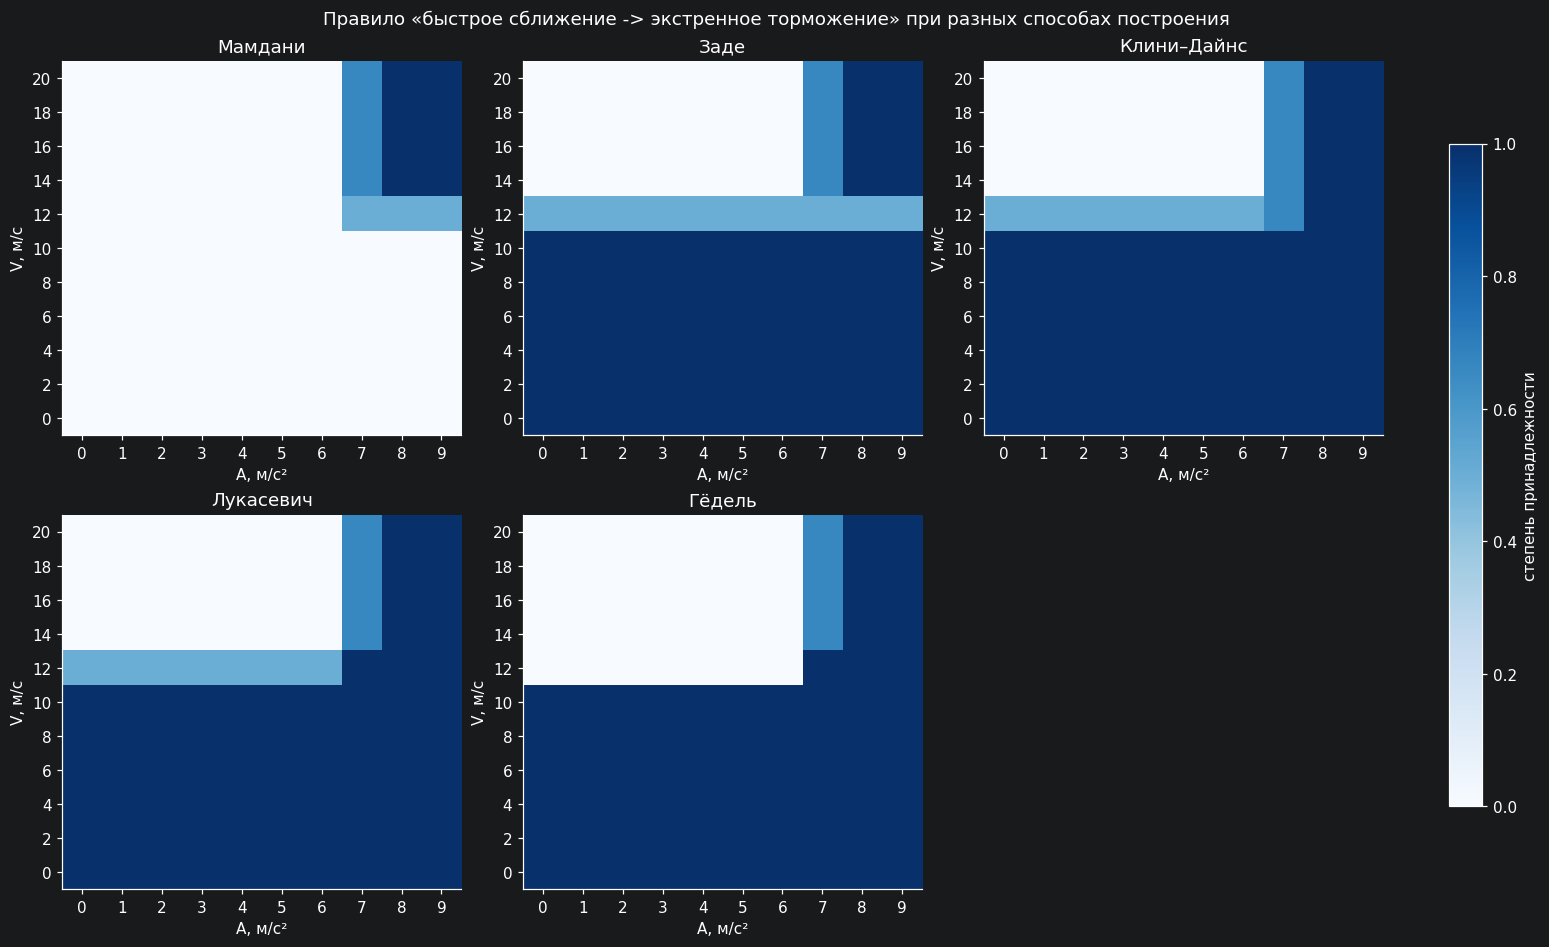

Импликация Гёделя (строки V, столбцы A):


,A=0,A=1,A=2,A=3,A=4,A=5,A=6,A=7,A=8,A=9
V=0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0
V=2,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0
V=4,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0
V=6,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0
V=8,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0
V=10,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.00,1.0,1.0
V=12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.00,1.0,1.0
V=14,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.67,1.0,1.0
V=16,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.67,1.0,1.0
V=18,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.67,1.0,1.0


In [17]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8.5), layout='constrained')
axes = axes.ravel()
axes[-1].axis('off')  # шестая ячейка сетки не нужна
R_by_impl = {}
for ax, impl in zip(axes, IMPLICATIONS):
    R = relation_impl(V['быстрое'], A['экстренное'], impl)
    R_by_impl[impl] = R
    im = ax.imshow(R, cmap='Blues', vmin=0, vmax=1, origin='lower', aspect='auto')
    ax.grid(False)
    ax.set_title(impl)
    ax.set_xticks(range(len(A.universe)), [f'{v:g}' for v in A.universe])
    ax.set_yticks(range(len(V.universe)), [f'{v:g}' for v in V.universe])
    ax.set_xlabel('A, м/с²')
    ax.set_ylabel('V, м/с')
fig.colorbar(im, ax=axes[:5].tolist(), label='степень принадлежности', shrink=0.8)
fig.suptitle('Правило «быстрое сближение -> экстренное торможение» при разных способах построения')
plt.show()

print('Импликация Гёделя (строки V, столбцы A):')
display(rel_frame(R_by_impl['Гёдель'], V, A))

Картина у импликаций противоположна Мамдани. Отношение Мамдани «светится» только в углу, где посылка и следствие
выполняются одновременно, и равно нулю везде, где сближение не быстрое. Импликации, наоборот, равны 1 везде, где
посылка не выполняется (V ≤ 10 м/с): **правило ничего не запрещает** при медленном сближении. Близкие к нулю значения
остаются только там, где правило *нарушено*: сближение быстрое, а торможение слабое (A ≤ 6 м/с² при V ≥ 14 м/с; у
Гёделя - уже с V = 12 м/с, а у остальных импликаций строка V = 12 м/с получает промежуточное значение 0.5).

Таким образом, отношение Мамдани описывает **допустимые сочетания** (что точно возможно), а импликация - **ограничения**
(что точно запрещено). Это два разных взгляда на одно и то же экспертное знание.

### 10.3. Свёртка и транспонирование

In [18]:
rows = []
for impl in IMPLICATIONS:
    R1_i = relation_impl(V['быстрое'], T['критическое'], impl)
    R2_i = relation_impl(T['критическое'], A['экстренное'], impl)
    R3_i = maxmin(R1_i, R2_i)
    R_dir = R_by_impl[impl]
    R_rev = relation_impl(A['экстренное'], V['быстрое'], impl)
    rows.append({
        'импликация': impl,
        'свёртка vs прямое правило: max |разность|': np.abs(R3_i - R_dir).max(),
        'свёртка ≤ прямого правила': bool(np.all(R3_i <= R_dir + 1e-12)),
        'Rᵀ vs обратное правило: max |разность|': np.abs(R_dir.T - R_rev).max(),
    })
props = pd.DataFrame(rows).set_index('импликация')
display(props)

,свёртка vs прямое правило: max |разность|,свёртка ≤ прямого правила,Rᵀ vs обратное правило: max |разность|
импликация,,,
Мамдани,0.00,True,0.0
Заде,0.00,True,1.0
Клини–Дайнс,0.00,True,1.0
Лукасевич,0.33,True,1.0
Гёдель,0.33,True,1.0


**Транспонирование.** Для всех импликаций транспонированная матрица отличается от матрицы обратного правила
«экстренное торможение -> быстрое сближение» (расхождение до 1.0), а для Мамдани совпадает. Значит, импликации, в
отличие от конъюнкции, **сохраняют направление правила**: «если сближение быстрое, то торможение экстренное» и «если
торможение экстренное, то сближение быстрое» становятся разными утверждениями, как и должно быть в логике. Первая
особенность из раздела 11.1 устранена.

**Свёртка.** Для импликаций Заде и Клини–Дайнса свёртка цепочки по-прежнему равна прямому правилу. Для Лукасевича и
Гёделя она отличается (до 0.33) и при этом нигде не превышает прямое правило. Иначе говоря, правило, выведенное через
промежуточную переменную TTC, получается *строже* прямого: цепочка рассуждений передаёт ограничения с потерями, но
никогда не добавляет лишней уверенности.

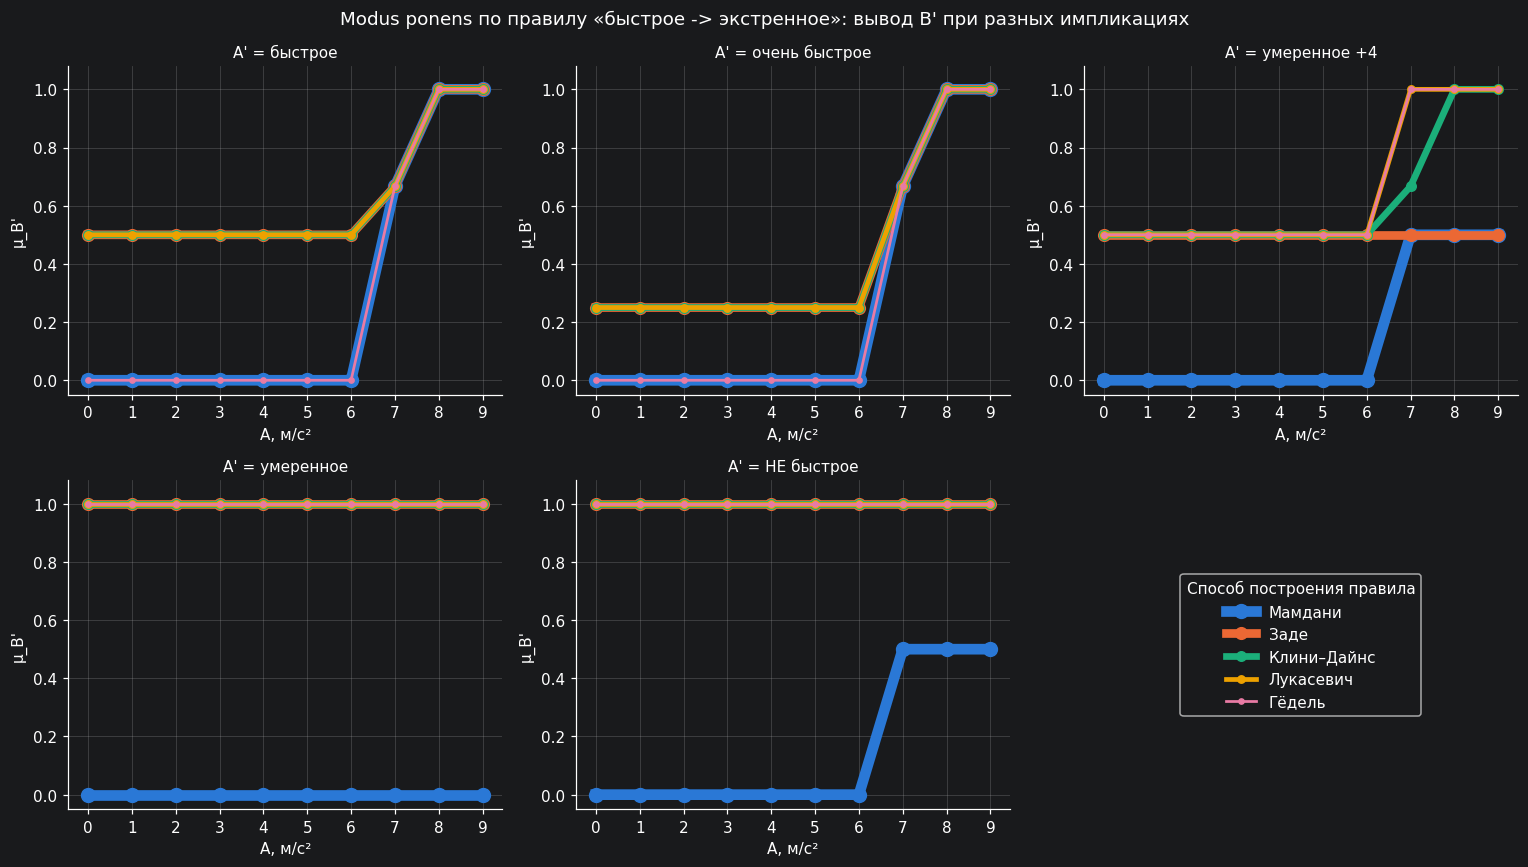

Нижний уровень вывода min B' (0 - вывод конкретен, 1 - «ничего не известно»):


A',быстрое,очень быстрое,умеренное +4,умеренное,НЕ быстрое
импликация,,,,,
Мамдани,0.0,0.00,0.0,0.0,0.0
Заде,0.5,0.25,0.5,1.0,1.0
Клини–Дайнс,0.5,0.25,0.5,1.0,1.0
Лукасевич,0.5,0.25,0.5,1.0,1.0
Гёдель,0.0,0.00,0.5,1.0,1.0


Совпадает ли вывод с исходным следствием B:


A',быстрое,очень быстрое,умеренное +4,умеренное,НЕ быстрое
импликация,,,,,
Мамдани,True,True,False,False,False
Заде,False,False,False,False,False
Клини–Дайнс,False,False,False,False,False
Лукасевич,False,False,False,False,False
Гёдель,True,True,False,False,False


In [19]:
fast, emerg = V['быстрое'], A['экстренное']
mp_inputs = [fast, fast.very(), V['умеренное'].shifted(4), V['умеренное'], fast.complement()]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()
rows = []
for ax, Ap in zip(axes, mp_inputs):
    for i, impl in enumerate(IMPLICATIONS):
        Bp = modus_ponens(Ap, R_by_impl[impl], A)
        ax.plot(A.universe, Bp.mu, 'o-', color=COLORS[i], lw=7 - 1.3 * i, ms=9 - 1.4 * i, label=impl)
        rows.append({"A'": Ap.name, 'импликация': impl,
                     "B' = B": bool(np.allclose(Bp.mu, emerg.mu)),
                     "уровень неопределённости min B'": Bp.mu.min(),
                     "μ_B'(8 м/с²)": Bp.mu[8]})
    ax.set_title(f"A' = {Ap.name}", fontsize=10)
    ax.set_xlabel('A, м/с²')
    ax.set_xticks(A.universe)
    ax.set_ylim(-0.05, 1.08)
    ax.set_ylabel("μ_B'")
# шестая ячейка сетки - под легенду
handles, labels = axes[0].get_legend_handles_labels()
axes[-1].axis('off')
axes[-1].legend(handles, labels, title='Способ построения правила', loc='center', fontsize=10)
fig.suptitle("Modus ponens по правилу «быстрое -> экстренное»: вывод B' при разных импликациях")
plt.tight_layout()
plt.show()

mp_table = pd.DataFrame(rows).pivot(index='импликация', columns="A'", values="уровень неопределённости min B'")
print("Нижний уровень вывода min B' (0 - вывод конкретен, 1 - «ничего не известно»):")
display(mp_table[[a.name for a in mp_inputs]].loc[list(IMPLICATIONS)])
exact = pd.DataFrame(rows).pivot(index='импликация', columns="A'", values="B' = B")
print("Совпадает ли вывод с исходным следствием B:")
display(exact[[a.name for a in mp_inputs]].loc[list(IMPLICATIONS)])

### 10.4. Modus ponens: что меняет импликация

Вывод при импликациях имеет принципиально другую форму: $B'$ складывается из «формы» следствия и **уровня
неопределённости** - минимального значения $B'$, которое показывает, насколько допустимо любое торможение.

* **Вход, совпадающий с посылкой** («быстрое», «очень быстрое»). Мамдани и Гёдель дают ровно исходное следствие
  «экстренное торможение». Заде, Клини–Дайнс и Лукасевич дают то же следствие, но с уровнем неопределённости 0.5
  (для «очень быстрого» - 0.25). Причина - точка V = 12 м/с, где сближение быстрое лишь наполовину: для неё эти
  импликации допускают любое торможение со степенью 0.5. Импликация Гёделя такого «шума» не даёт, потому что она
  согласована с max-min композицией: для неё обобщённый modus ponens выполняется точно.
* **Частичное совпадение** («умеренное +4»). Мамдани даёт экстренное торможение со степенью 0.5 и ноль для остальных
  значений. Клини–Дайнс, Лукасевич и Гёдель выделяют экстренное торможение (степень 0.67–1) на фоне неопределённости
  0.5. Смысл: «торможение должно быть экстренным, хотя уверенность в применимости правила - лишь 0.5». Импликация Заде
  даёт ровный уровень 0.5 для любого торможения, то есть при частичном совпадении фактически отказывается от вывода.
* **Вход, на который правило не рассчитано** («умеренное», «НЕ быстрое»). Мамдани даёт пустое множество
  («умеренное») или экстренное торможение со степенью 0.5 («НЕ быстрое»). Импликации во всех случаях дают
  $\mu_{B'} \equiv 1$, то есть **«правило ничего не говорит, допустимо любое торможение»**. Это логически правильный
  ответ, и **парадокс из раздела 11.1 (особенность 2) исчезает**.

Отличие пустого вывода от вывода «всё допустимо» важно для системы управления. Пустой вывод Мамдани при
агрегации нескольких правил просто не вносит вклада, а вывод «всё допустимо» от импликации не сужает решения других
правил. Обе семантики корректны, но отвечают на разные вопросы: Мамдани - «что рекомендует правило», импликация - «что
правило запрещает».

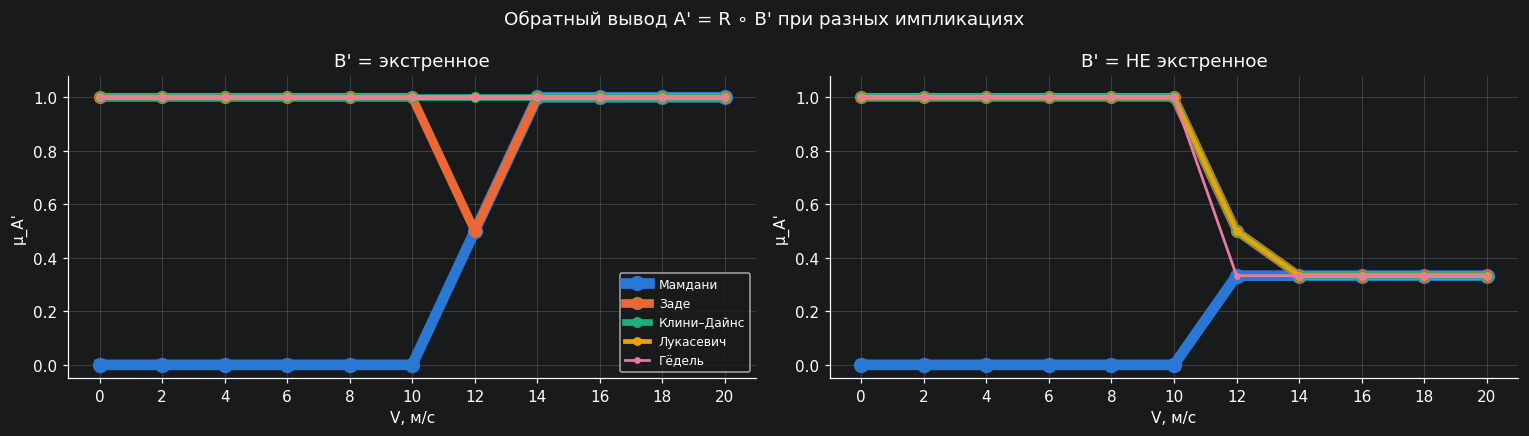

V=0  V=2  V=4  V=6  V=8  V=10  V=12  V=14  V=16  V=18  V=20
B'            импликация                                                              
экстренное    Мамдани      0.0  0.0  0.0  0.0  0.0   0.0  0.50  1.00  1.00  1.00  1.00
              Заде         1.0  1.0  1.0  1.0  1.0   1.0  0.50  1.00  1.00  1.00  1.00
              Клини–Дайнс  1.0  1.0  1.0  1.0  1.0   1.0  1.00  1.00  1.00  1.00  1.00
              Лукасевич    1.0  1.0  1.0  1.0  1.0   1.0  1.00  1.00  1.00  1.00  1.00
              Гёдель       1.0  1.0  1.0  1.0  1.0   1.0  1.00  1.00  1.00  1.00  1.00
НЕ экстренное Мамдани      0.0  0.0  0.0  0.0  0.0   0.0  0.33  0.33  0.33  0.33  0.33
              Заде         1.0  1.0  1.0  1.0  1.0   1.0  0.50  0.33  0.33  0.33  0.33
              Клини–Дайнс  1.0  1.0  1.0  1.0  1.0   1.0  0.50  0.33  0.33  0.33  0.33
              Лукасевич    1.0  1.0  1.0  1.0  1.0   1.0  0.50  0.33  0.33  0.33  0.33
              Гёдель       1.0  1.0  1.0  1.0  1.0   1.0  0.33  0.33  0.33  0.33  0.33

In [20]:
mt_inputs = [emerg, emerg.complement()]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
rows = []
for ax, Bp in zip(axes, mt_inputs):
    for i, impl in enumerate(IMPLICATIONS):
        Ap = modus_tollens(R_by_impl[impl], Bp, V)
        ax.plot(V.universe, Ap.mu, 'o-', color=COLORS[i], lw=7 - 1.3 * i, ms=9 - 1.4 * i, label=impl)
        rows.append({"B'": Bp.name, 'импликация': impl, **{f'V={v:g}': m for v, m in zip(V.universe, Ap.mu)}})
    ax.set_title(f"B' = {Bp.name}")
    ax.set_xlabel('V, м/с')
    ax.set_ylabel("μ_A'")
    ax.set_xticks(V.universe)
    ax.set_ylim(-0.05, 1.08)
axes[0].legend(fontsize=8, loc='lower right')
fig.suptitle("Обратный вывод A' = R ∘ B' при разных импликациях")
plt.tight_layout()
plt.show()
display(pd.DataFrame(rows).set_index(["B'", 'импликация']))

### 10.5. Modus tollens: классическая схема

**Наблюдение «НЕ экстренное торможение».** Это и есть классический modus tollens: «если сближение быстрое, то
торможение экстренное; торможение не экстренное - значит, сближение не быстрое». Все импликации дают результат,
похожий на «НЕ быстрое сближение»: степень 1 для V ≤ 10 м/с и 0.33 для V ≥ 14 м/с. Остаточные 0.33 объясняются точкой
A = 7 м/с², где торможение одновременно «экстренное» (0.67) и «не экстренное» (0.33): такое торможение не позволяет
полностью исключить быстрое сближение. Мамдани в этой ситуации делает противоположный вывод: «быстрое сближение» со
степенью 0.33. **Особенность 3 из раздела 11.1 устранена:** импликации реализуют классический modus tollens.

**Наблюдение «экстренное торможение»** (формула (4) методических указаний с $B' = B$). Мамдани делает вывод «сближение
было быстрым», а импликации Клини–Дайнса, Лукасевича и Гёделя - «скорость сближения может быть любой» ($\mu \equiv 1$).
С точки зрения логики прав второй ответ: из «A -> B» и «B» ничего не следует об A. Вывод A из B - классическая ошибка
**утверждения следствия**: экстренное торможение могло быть вызвано и другой причиной, например, резким торможением
машины впереди при небольшой скорости сближения. Вывод Мамдани здесь - не дедукция, а *абдукция* (поиск вероятной
причины). Она полезна для диагностики, но логически не гарантирована. У Заде результат почти такой же (степень 1 везде,
кроме V = 12 м/с, где 0.5).

### 10.6. Итоги творческой части

| Свойство | Мамдани | Заде | Клини–Дайнс | Лукасевич | Гёдель |
|---|---|---|---|---|---|
| Совпадает с классической импликацией на {0, 1} | нет | да | да | да | да |
| Сохраняет направление правила (Rᵀ ≠ обратному правилу) | нет | да | да | да | да |
| Modus ponens при A′ = A даёт ровно B | да | нет (шум 0.5) | нет (шум 0.5) | нет (шум 0.5) | да |
| Вход вне правила («НЕ быстрое») | ложный вывод 0.5 | «неизвестно» | «неизвестно» | «неизвестно» | «неизвестно» |
| Классический modus tollens (НЕ B -> НЕ A) | нет | да | да | да | да |
| Свёртка цепочки равна прямому правилу | да | да | да | нет (строже) | нет (строже) |

**Вывод.** Гипотеза подтвердилась: все три особенности раздела 10.1 вызваны тем, что отношение Мамдани является
конъюнкцией, и все они устраняются переходом к импликациям. Среди импликаций для данной задачи лучше всего подходит
**импликация Гёделя**: она единственная одновременно сохраняет направление правил, точно выполняет modus ponens при
max-min композиции и даёт ответ «неизвестно» на входы вне правила.

При этом отношение Мамдани не «неправильное»: оно удобно для **управления**, когда нужно получить конкретную
рекомендацию из набора правил и сложить их вклады.

## 11. Интерактивная проверка

Ниже собрана функция `explore`, которая выполняет любой из выводов для выбранного терма и модификатора и рисует
результат. Её можно вызывать двумя способами:

1. **напрямую**, меняя аргументы в ячейке - способ работает в любой среде, включая PyCharm;
2. **через виджеты** `ipywidgets` (выпадающие списки и ползунок) - если библиотека установлена и среда поддерживает
   виджеты (Jupyter Notebook / JupyterLab). В PyCharm виджеты могут не отображаться, тогда используйте первый способ.

Аргументы `explore`:
* `rule` - правило: `'R1'` (V -> T), `'R2'` (T -> A) или `'R3'` (V -> A, выведенное свёрткой);
* `mode` - `'ponens'` (по условию найти следствие) или `'tollens'` (по следствию найти условие);
* `term` - терм входной переменной, к которому применяется изменение;
* `hedge` - модификатор: `'нет'`, `'очень'`, `'более-менее'`, `'НЕ'`, `'нормализация'`;
* `shift` - сдвиг множества вдоль оси, в единицах переменной;
* `impl` - способ построения правил: `'Мамдани'`, `'Заде'`, `'Клини–Дайнс'`, `'Лукасевич'`, `'Гёдель'` (раздел 11).

Для собственного множества, заданного списком степеней принадлежности, используется функция `explore_custom`.

In [21]:
def get_rules(impl='Мамдани'):
    # Правила R1, R2 и их свёртка R3, построенные выбранным способом (Мамдани или импликация)
    r1 = relation_impl(V['быстрое'], T['критическое'], impl)
    r2 = relation_impl(T['критическое'], A['экстренное'], impl)
    return {'R1': (r1, V, T), 'R2': (r2, T, A), 'R3': (maxmin(r1, r2), V, A)}


RULES = get_rules()
HEDGES = {
    'нет': lambda s: s,
    'очень': lambda s: s.very(),
    'более-менее': lambda s: s.more_or_less(),
    'НЕ': lambda s: s.complement(),
    'нормализация': lambda s: s.normalized(),
}


def _plot_inference(src, res, var_in, var_out, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
    ax1.bar(var_in.universe, src.mu, width=0.6 * np.diff(var_in.universe).min(), color=COLORS[0])
    ax1.set_title(f'Вход: {src.name}')
    ax1.set_xlabel(f'{var_in.symbol}, {var_in.unit}'); ax1.set_ylabel('μ'); ax1.set_ylim(0, 1.05)
    ax1.set_xticks(var_in.universe)
    ax2.bar(var_out.universe, res.mu, width=0.6 * np.diff(var_out.universe).min(), color=COLORS[1])
    ax2.set_title('Результат вывода')
    ax2.set_xlabel(f'{var_out.symbol}, {var_out.unit}'); ax2.set_ylabel('μ'); ax2.set_ylim(0, 1.05)
    ax2.set_xticks(var_out.universe)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def _run(src, rule, mode, impl):
    R, X, Y = get_rules(impl)[rule]
    if mode == 'ponens':
        res = modus_ponens(src, R, Y)
        _plot_inference(src, res, X, Y, f'modus ponens по {rule} ({impl})')
    else:
        res = modus_tollens(R, src, X)
        _plot_inference(src, res, Y, X, f'modus tollens по {rule} ({impl})')
    print('Результат:', np.round(res.mu, 2))
    return res


def explore(rule='R3', mode='ponens', term='быстрое', hedge='очень', shift=0.0, impl='Мамдани'):
    R, X, Y = RULES[rule]
    var_in = X if mode == 'ponens' else Y
    if term not in var_in.sets:
        print(f'Терм «{term}» не найден у переменной {var_in.symbol}. Доступны: {list(var_in.sets)}')
        return None
    src = HEDGES[hedge](var_in[term])
    if shift:
        src = src.shifted(shift)
    return _run(src, rule, mode, impl)


def explore_custom(mu, rule='R3', mode='ponens', name='пользовательское', impl='Мамдани'):
    R, X, Y = RULES[rule]
    var_in = X if mode == 'ponens' else Y
    if len(mu) != len(var_in.universe):
        print(f'Нужно {len(var_in.universe)} значений для универсума {var_in.symbol}: {var_in.universe}')
        return None
    return _run(FuzzySet(name, var_in.universe, mu), rule, mode, impl)

In [22]:
_ = explore(rule='R3', mode='ponens', term='быстрое', hedge='НЕ')
_ = explore(rule='R3', mode='ponens', term='быстрое', hedge='НЕ', impl='Гёдель')
_ = explore_custom([0, 0, 0, 0, 0.2, 0.6, 1, 0.6, 0.2, 0, 0], rule='R1', mode='ponens', name='сближение около 12 м/с')

Первый пример показывает ограничение отношения Мамдани, уже отмеченное в разделах 7 и 9.2 и разобранное в разделе 1. На вход подано «НЕ быстрое
сближение», а вывод - «экстренное торможение» со степенью 0.5. Причина в том, что «НЕ быстрое» и «быстрое» частично
пересекаются в точке V = 12 м/с (степень 0.5), а правило Мамдани реагирует на любое совпадение входа с посылкой.
Второй пример - тот же вход при импликации Гёделя: вывод «допустимо любое торможение» (μ = 1), парадокс устранён
(раздел 11.4). Третий пример - пользовательское множество «сближение около 12 м/с»: по правилу R1 система заключает, что TTC
критическое со степенью 0.6.

In [25]:
# Способ 2: виджеты (если среда их поддерживает)
try:
    import ipywidgets as widgets

    def _terms(rule, mode):
        R, X, Y = RULES[rule]
        return list((X if mode == 'ponens' else Y).sets)

    rule_w = widgets.Dropdown(options=list(RULES), value='R3', description='Правило')
    mode_w = widgets.Dropdown(options=[('modus ponens', 'ponens'), ('modus tollens', 'tollens')], description='Вывод')
    term_w = widgets.Dropdown(options=_terms('R3', 'ponens'), value='быстрое', description='Терм')
    hedge_w = widgets.Dropdown(options=list(HEDGES), value='нет', description='Модификатор')
    shift_w = widgets.FloatSlider(value=0, min=-10, max=10, step=0.5, description='Сдвиг')
    impl_w = widgets.Dropdown(options=list(IMPLICATIONS), value='Мамдани', description='Правила')

    def _update_terms(_):
        term_w.options = _terms(rule_w.value, mode_w.value)

    rule_w.observe(_update_terms, 'value')
    mode_w.observe(_update_terms, 'value')
    widgets.interact(explore, rule=rule_w, mode=mode_w, term=term_w, hedge=hedge_w, shift=shift_w, impl=impl_w)
except ImportError:
    print('ipywidgets не установлен: используйте прямой вызов explore(...) в предыдущей ячейке.')

interactive(children=(Dropdown(description='Правило', index=2, options=('R1', 'R2', 'R3'), value='R3'), Dropdo…

## 13. Выводы

1. Реализовано приложение, принимающее на вход произвольное число нечётких множеств (в работе - 11 множеств на трёх
   лингвистических переменных адаптивного круиз-контроля). Множества задаются параметрами треугольных и трапециевидных
   функций и дискретизируются на универсумах из 10–11 точек.
2. Построены продукционные отношения R1 «быстрое сближение -> критическое TTC» и R2 «критическое TTC -> экстренное
   торможение» в виде матриц через пересечение (min), для каждого построены тепловая карта и трёхмерная поверхность.
3. Свёрткой R1 ∘ R2 выведено новое правило R3 «быстрое сближение -> экстренное торможение». Показано, что для отношений
   Мамдани свёртка равна прямому правилу, срезанному на уровне высоты промежуточного множества; при нормальном
   промежуточном множестве они совпадают точно.
4. Транспонированием получены обратные правила. Для отношений, построенных через min, транспонированная матрица
   совпадает с матрицей обратного правила - отношение Мамдани описывает связь, а не направленную импликацию.
5. Найдены дополнения множеств. Показано, что законы исключённого третьего и противоречия в нечёткой логике не
   выполняются, а правило на дополнениях отличается от дополнения матрицы правила (закон де Моргана).
6. Реализованы modus ponens и modus tollens. Вывод равен исходному следствию (или посылке), срезанному на уровне степени
   совпадения входа с правилом, поэтому $A'$ и $B'$, как правило, не совпадают с исходными $A$ и $B$. Modus tollens по
   формуле методических указаний эквивалентен modus ponens по транспонированному правилу, а вывод по цепочке правил -
   выводу по свёрнутому правилу.
7. Выявлено практическое ограничение: при крупном шаге универсума соседние термы могут не пересекаться ни в одной
   точке, и вывод между ними теряется. Этот результат учитывается при выборе дискретизации и функций принадлежности в
   ПР №2.
8. **Творческая часть.** Показано, что все выявленные особенности (неразличимость прямого и обратного правила,
   ложный вывод на входе «НЕ быстрое», отсутствие классического modus tollens) вызваны тем, что отношение Мамдани -
   конъюнкция, а не импликация. Переход к импликациям Заде, Клини–Дайнса, Лукасевича и Гёделя устраняет все три.
   Для логического вывода в задаче круиз-контроля лучше всего подходит импликация Гёделя: она точно выполняет modus
   ponens при max-min композиции. Отношение Мамдани остаётся предпочтительным для управления, поэтому именно оно
   будет использовано в ПР №2.